# Aufgabe 1 – Musterlösung
## Datenqualität, Duplikate und Dubletten

Diese Lösung wird erst nach der Gruppenarbeit veröffentlicht. Sie verwendet ausschliesslich den sichtbaren Ausgangsdatensatz; keine Instructor-Labels fliessen in die Regeln ein.

Die Lösung zeigt einen nachvollziehbaren Referenzweg. Andere Lösungen sind vertretbar, wenn Definitionen, Evidenz und Auswirkungen gleichwertig dokumentiert werden.

## 0. Setup und reproduzierbares Laden

In [2]:
from pathlib import Path
import hashlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 20)
sns.set_theme(style="whitegrid", context="notebook")

def find_repo_root(start: Path = Path.cwd()) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "data/input/trips_case_initial.parquet").exists():
            return candidate
    raise FileNotFoundError("Repository-Wurzel nicht gefunden.")

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

ROOT = find_repo_root()
DATA_PATH = ROOT / "data/input/trips_case_initial.parquet"
CHECKPOINT_PATH = ROOT / "data/checkpoints/checkpoint_01_resolved_events.parquet"
SOURCE_SHA256_BEFORE = sha256_file(DATA_PATH)

trips = pd.read_parquet(DATA_PATH)
print(f"Repository: {ROOT}")
print(f"Ausgangsdaten: {trips.shape[0]:,} Zeilen × {trips.shape[1]} Spalten")

Repository: C:\Users\pell\Documents\3__UNTERRICHT_STUDENTENBETREUUNG\MAS\CAS Data Engineering\2026\04_Transformation\cas-daeng-transformation-2026
Ausgangsdaten: 200,900 Zeilen × 24 Spalten


## 1. EDA und Hypothesen

Wir trennen zunächst Beobachtungen von Erklärungen. Der Pickup-Zeitbereich, die Ingestion-Zeit und eine vorläufige Stundenaggregation liefern erste Hinweise. Die Aggregation ersetzt die Prüfung auf Zeilenebene nicht.

### Erster Blick auf den Datensatz

Eine Zeile repräsentiert zunächst ein angeliefertes Datenereignis. Ob jedes Ereignis tatsächlich einer eigenständigen Taxifahrt entspricht, wird im weiteren Verlauf untersucht.

In [3]:
print(f"Zeilen: {len(trips):,}")
print(f"Spalten: {trips.shape[1]}")

display(trips.head(5))
#display(trips.sample(5, random_state=42))

Zeilen: 200,900
Spalten: 24


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,ingest_record_id,ingested_at,source_file,batch_id
0,2,2025-06-30 22:15:24,2025-06-30 22:25:07,1.0,1.65,1.0,N,234,246,1,11.40,1.0,0.5,3.43,0.0,1.0,20.58,2.5,0.00,0.75,O_b917625e5b70fe4dd0,2025-06-30 22:38:07,yellow_tripdata_2025-07.parquet,source_2025-07
1,2,2025-06-30 22:39:17,2025-06-30 22:42:38,1.0,0.65,1.0,N,234,107,1,5.80,1.0,0.5,2.31,0.0,1.0,13.86,2.5,0.00,0.75,O_018c1475a885827a4e,2025-06-30 23:26:29,yellow_tripdata_2025-07.parquet,source_2025-07
2,2,2025-07-01 00:00:06,2025-07-01 00:12:15,NaN,2.83,NaN,None,246,114,0,13.51,0.0,0.5,0.00,0.0,1.0,18.26,NaN,NaN,0.75,O_d30318ab2409b1270c,2025-07-01 00:14:13,yellow_tripdata_2025-07.parquet,source_2025-07
3,2,2025-07-01 00:02:01,2025-07-01 00:19:16,1.0,10.64,1.0,N,138,107,1,41.50,6.0,0.5,10.45,0.0,1.0,64.45,2.5,1.75,0.75,O_7e3c7aab6dc38aab2a,2025-07-01 00:22:13,yellow_tripdata_2025-07.parquet,source_2025-07
4,2,2025-07-01 00:15:41,2025-07-01 00:23:04,NaN,1.11,NaN,None,164,230,0,8.86,0.0,0.5,0.00,0.0,1.0,13.61,NaN,NaN,0.75,O_20d31999bcb9401dce,2025-07-01 00:24:46,yellow_tripdata_2025-07.parquet,source_2025-07


In [4]:
DESCRIPTIVE_COLUMNS = [
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount",
]

display(
    trips[DESCRIPTIVE_COLUMNS]
    .describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
passenger_count,148360.0,1.32,0.76,0.00,1.00,1.00,1.00,8.00
trip_distance,200900.0,27.41,2018.84,0.00,1.07,1.93,3.93,397994.37
fare_amount,200900.0,18.63,21.63,-574.20,8.77,14.20,23.30,1984.70
tip_amount,200900.0,2.71,4.07,-14.95,0.00,2.00,3.85,400.50
total_amount,200900.0,26.93,25.75,-576.70,15.79,21.40,30.84,2403.01


In [5]:
profile = pd.DataFrame({
    "dtype": trips.dtypes.astype(str),
    "missing": trips.isna().sum(),
    "missing_pct": trips.isna().mean().mul(100),
    "nunique": trips.nunique(dropna=True),
}).sort_values(["missing", "nunique"], ascending=[False, True])

print(
    "Pickup-Zeitbereich:",
    trips["tpep_pickup_datetime"].min(),
    "bis",
    trips["tpep_pickup_datetime"].max(),
)
display(profile.head(12).round({"missing_pct": 2}))

Pickup-Zeitbereich: 2009-01-01 08:52:26 bis 2025-07-24 23:59:56


,dtype,missing,missing_pct,nunique
store_and_fwd_flag,object,52540,26.15,2
congestion_surcharge,float64,52540,26.15,3
Airport_fee,float64,52540,26.15,5
RatecodeID,float64,52540,26.15,6
passenger_count,float64,52540,26.15,8
source_file,object,0,0.00,2
batch_id,object,0,0.00,2
VendorID,int32,0,0.00,4
mta_tax,float64,0,0.00,4
improvement_surcharge,float64,0,0.00,4


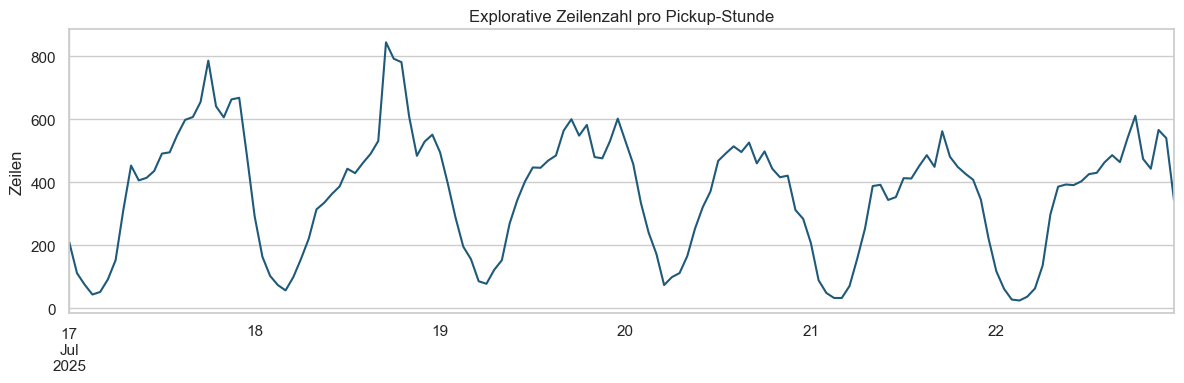

In [6]:
hourly_exploration = (
    trips.assign(
        pickup_hour=trips["tpep_pickup_datetime"].dt.floor("h")
    )
    .groupby("pickup_hour")
    .size()
    .rename("rows")
)

ax = hourly_exploration.loc["2025-07-17":"2025-07-22"].plot(
    figsize=(12, 4),
    color="#1F5A7A",
    title="Explorative Zeilenzahl pro Pickup-Stunde",
)
ax.set(xlabel="", ylabel="Zeilen")
plt.tight_layout()
plt.show()

In [7]:
batch_overview = (
    trips.groupby(["source_file", "batch_id"], dropna=False)
    .agg(
        rows=("ingest_record_id", "size"),
        first_ingested=("ingested_at", "min"),
        last_ingested=("ingested_at", "max"),
        first_pickup=("tpep_pickup_datetime", "min"),
        last_pickup=("tpep_pickup_datetime", "max"),
    )
    .sort_values("first_ingested")
)

display(batch_overview)

,,rows,first_ingested,last_ingested,first_pickup,last_pickup
source_file,batch_id,,,,,
yellow_tripdata_2025-07.parquet,source_2025-07,200000,2025-06-30 22:38:07,2025-07-25 22:03:22,2009-01-01 08:52:26,2025-07-24 23:59:56
replay_20250718_1700.jsonl,replay_20250721_0900,900,2025-07-21 09:00:00,2025-07-21 09:14:59,2025-07-18 17:00:19,2025-07-18 20:59:43


In [8]:
amount_columns = [
    "fare_amount",
    "tip_amount",
    "total_amount",
]

amount_overview = pd.DataFrame({
    "Minimum": trips[amount_columns].min(),
    "Anzahl negative Werte": (trips[amount_columns] < 0).sum(),
})

display(amount_overview)

,Minimum,Anzahl negative Werte
fare_amount,-574.20,12684
tip_amount,-14.95,9
total_amount,-576.70,4202


In [9]:
display(
    trips.loc[
        trips["total_amount"] < 0,
        [
            "tpep_pickup_datetime",
            "trip_distance",
            "fare_amount",
            "tip_amount",
            "total_amount",
            "source_file",
            "batch_id",
        ],
    ].head(10)
)

,tpep_pickup_datetime,trip_distance,fare_amount,tip_amount,total_amount,source_file,batch_id
63,2025-07-01 00:20:53,0.00,-3.0,0.0,-7.25,yellow_tripdata_2025-07.parquet,source_2025-07
64,2025-07-01 00:32:56,6.38,-28.2,0.0,-32.45,yellow_tripdata_2025-07.parquet,source_2025-07
106,2025-07-01 00:32:42,15.91,-59.0,0.0,-70.19,yellow_tripdata_2025-07.parquet,source_2025-07
208,2025-07-01 02:12:25,19.50,-73.0,0.0,-84.19,yellow_tripdata_2025-07.parquet,source_2025-07
219,2025-07-01 01:28:16,8.88,-37.3,0.0,-49.80,yellow_tripdata_2025-07.parquet,source_2025-07
290,2025-07-01 02:29:46,3.39,-14.9,0.0,-19.15,yellow_tripdata_2025-07.parquet,source_2025-07
369,2025-07-01 03:22:42,4.46,-19.1,0.0,-28.35,yellow_tripdata_2025-07.parquet,source_2025-07
378,2025-07-01 03:38:00,5.47,-24.7,0.0,-28.95,yellow_tripdata_2025-07.parquet,source_2025-07
400,2025-07-01 05:10:36,4.14,-18.4,0.0,-22.65,yellow_tripdata_2025-07.parquet,source_2025-07
415,2025-07-01 05:48:57,0.00,-3.0,0.0,-5.50,yellow_tripdata_2025-07.parquet,source_2025-07


### Hypothesen vor der Auflösung

1. Die leeren Fahrtdetails treten zufällig auf.
2. Der sichtbare Peak ist reale Nachfrage.
3. Später eingetroffene, ähnliche Datensätze sind technische Replays.
4. Negative Beträge sind fehlerhafte Duplikate.

Die folgenden Abschnitte prüfen diese Hypothesen einzeln.

## 2. Missingness ist strukturell

In [19]:
missing_block = [
    "passenger_count",
    "RatecodeID",
    "store_and_fwd_flag",
    "congestion_surcharge",
    "Airport_fee",
]

all_missing = trips[missing_block].isna().all(axis=1)
missing_by_payment = pd.crosstab(
    trips["payment_type"], all_missing, margins=True
)
missing_by_payment.columns = ["Nullblock nein", "Nullblock ja", "Total"]

display(missing_by_payment)
print(
    "Anteil payment_type=0 unter den Nullblock-Zeilen:",
    f"{trips.loc[all_missing, 'payment_type'].eq(0).mean():.1%}",
)

,Nullblock nein,Nullblock ja,Total
payment_type,,,
0,0,52540,52540
1,121048,0,121048
2,20179,0,20179
3,1472,0,1472
4,5661,0,5661
All,148360,52540,200900


Anteil payment_type=0 unter den Nullblock-Zeilen: 100.0%


**Entscheidung:** Kein pauschales `dropna()`. Der gemeinsame Nullblock ist vollständig auf `payment_type = 0` konzentriert. Er wird als strukturelle Quellencharakteristik dokumentiert und für diese Aufgabe nicht imputiert.

## 3. Exakte Payload-Duplikate

In [20]:
SOURCE_COLUMNS = [
    "VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime",
    "passenger_count", "trip_distance", "RatecodeID",
    "store_and_fwd_flag", "PULocationID", "DOLocationID",
    "payment_type", "fare_amount", "extra", "mta_tax", "tip_amount",
    "tolls_amount", "improvement_surcharge", "total_amount",
    "congestion_surcharge", "Airport_fee", "cbd_congestion_fee",
]

BUSINESS_SIGNATURE_COLUMNS = [
    "VendorID", "tpep_pickup_datetime", "tpep_dropoff_datetime",
    "passenger_count", "trip_distance", "RatecodeID",
    "store_and_fwd_flag", "PULocationID", "DOLocationID",
    "payment_type",
]

work = trips.sort_values(
    ["ingested_at", "ingest_record_id"], kind="stable"
).reset_index(drop=True)

work["is_payload_duplicate_copy"] = work.duplicated(
    subset=SOURCE_COLUMNS, keep="first"
)
work["is_replay_batch"] = (
    work["batch_id"].astype("string").str.startswith("replay_", na=False)
    | work["source_file"].astype("string").str.startswith("replay_", na=False)
)

comparison = pd.Series({
    "vollständig identische Zeilen": int(work.duplicated(keep="first").sum()),
    "wiederholte technische IDs": int(work["ingest_record_id"].duplicated().sum()),
    "Payload-Kopien ohne Lineage-Felder": int(work["is_payload_duplicate_copy"].sum()),
})
display(comparison.to_frame("Kopien"))

,Kopien
vollständig identische Zeilen,0
wiederholte technische IDs,0
Payload-Kopien ohne Lineage-Felder,751


Die vier Lineage-Felder `ingest_record_id`, `ingested_at`, `source_file` und `batch_id` dürfen bei der Payload-Suche nicht verdecken, dass zwei Ingest-Ereignisse denselben fachlichen Inhalt tragen. Zugleich bleiben sie für die spätere Erklärung erhalten.

## 4. Fahrtsignaturen und Gegenbuchungen

In [21]:
signature_hash = pd.util.hash_pandas_object(
    work[BUSINESS_SIGNATURE_COLUMNS],
    index=False,
    categorize=True,
).astype("uint64")
work["signature_id"] = signature_hash.map(
    lambda value: f"S{int(value):016x}"
)

amount_groups = work.groupby("signature_id", sort=False)["total_amount"]
group_min = amount_groups.transform("min")
group_max = amount_groups.transform("max")
work["is_reversal_group"] = (group_min < 0) & (group_max > 0)
work["reversal_role"] = np.select(
    [
        work["is_reversal_group"] & work["total_amount"].gt(0),
        work["is_reversal_group"] & work["total_amount"].lt(0),
    ],
    ["positive", "negative"],
    default="none",
)

signature_summary = (
    work.groupby("signature_id", sort=False)
    .agg(
        rows=("ingest_record_id", "size"),
        min_total=("total_amount", "min"),
        max_total=("total_amount", "max"),
        source_files=("source_file", "nunique"),
    )
)

display(pd.Series({
    "Mehrfachsignaturen": int(signature_summary["rows"].gt(1).sum()),
    "positive/negative Gruppen": int(
        ((signature_summary["min_total"] < 0)
         & (signature_summary["max_total"] > 0)).sum()
    ),
}).to_frame("Anzahl"))

,Anzahl
Mehrfachsignaturen,1206
positive/negative Gruppen,405


In [22]:
# Nur Fahrtsignaturen betrachten, die mehrfach vorkommen
repeated_signatures = signature_summary.loc[
    signature_summary["rows"] > 1
].copy()

# Spannweite zwischen kleinstem und grösstem Betrag berechnen
repeated_signatures["total_range"] = (
    repeated_signatures["max_total"]
    - repeated_signatures["min_total"]
)

# Gruppen mit besonders unterschiedlichen Beträgen auswählen
candidate_signatures = (
    repeated_signatures
    .sort_values("total_range", ascending=False)
    .head(5)
    .index
)

display(
    work.loc[
        work["signature_id"].isin(candidate_signatures),
        [
            "signature_id",
            "tpep_pickup_datetime",
            "tpep_dropoff_datetime",
            "PULocationID",
            "DOLocationID",
            "trip_distance",
            "fare_amount",
            "tip_amount",
            "total_amount",
            "ingested_at",
            "source_file",
            "batch_id",
        ],
    ].sort_values(
        ["signature_id", "total_amount"],
        ascending=[True, False],
    )
)

,signature_id,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID,trip_distance,fare_amount,tip_amount,total_amount,ingested_at,source_file,batch_id
123055,S0804569446255b39,2025-07-16 10:50:14,2025-07-16 12:02:54,142,194,31.71,238.9,0.0,241.15,2025-07-16 13:06:36,yellow_tripdata_2025-07.parquet,source_2025-07
123268,S0804569446255b39,2025-07-16 10:50:14,2025-07-16 12:02:54,142,194,31.71,-238.9,0.0,-241.15,2025-07-16 13:35:13,yellow_tripdata_2025-07.parquet,source_2025-07
159017,S173ac6191c66ce39,2025-07-20 01:49:09,2025-07-20 01:49:22,182,182,0.00,200.0,0.0,201.00,2025-07-20 03:28:13,yellow_tripdata_2025-07.parquet,source_2025-07
158868,S173ac6191c66ce39,2025-07-20 01:49:09,2025-07-20 01:49:22,182,182,0.00,-200.0,0.0,-201.00,2025-07-20 03:07:05,yellow_tripdata_2025-07.parquet,source_2025-07
159177,S40d4786c4315d906,2025-07-20 02:31:41,2025-07-20 02:31:57,133,133,0.00,400.0,0.0,401.00,2025-07-20 03:56:29,yellow_tripdata_2025-07.parquet,source_2025-07
159310,S40d4786c4315d906,2025-07-20 02:31:41,2025-07-20 02:31:57,133,133,0.00,-400.0,0.0,-401.00,2025-07-20 04:27:19,yellow_tripdata_2025-07.parquet,source_2025-07
36964,S7856476078b7d9a6,2025-07-06 06:08:41,2025-07-06 06:08:50,132,132,0.00,250.0,0.0,252.75,2025-07-06 07:56:24,yellow_tripdata_2025-07.parquet,source_2025-07
36925,S7856476078b7d9a6,2025-07-06 06:08:41,2025-07-06 06:08:50,132,132,0.00,-250.0,0.0,-252.75,2025-07-06 07:19:28,yellow_tripdata_2025-07.parquet,source_2025-07
165869,S9693e2699c06acc1,2025-07-20 21:14:01,2025-07-20 22:00:36,138,1,32.17,135.0,0.0,172.99,2025-07-20 23:31:03,yellow_tripdata_2025-07.parquet,source_2025-07
166042,S9693e2699c06acc1,2025-07-20 21:14:01,2025-07-20 22:00:36,138,1,32.17,-135.0,0.0,-172.99,2025-07-20 23:59:38,yellow_tripdata_2025-07.parquet,source_2025-07


In [23]:
example_signature = signature_summary.loc[
    (signature_summary["min_total"] < 0)
    & (signature_summary["max_total"] > 0)
].index[0]

display(
    work.loc[work["signature_id"].eq(example_signature), [
        "signature_id", "tpep_pickup_datetime", "trip_distance",
        "fare_amount", "tip_amount", "total_amount", "payment_type",
        "source_file", "batch_id",
    ]]
)

,signature_id,tpep_pickup_datetime,trip_distance,fare_amount,tip_amount,total_amount,payment_type,source_file,batch_id
1818,Se1e07207f64bbcbe,2025-07-01 10:27:17,0.69,-10.0,0.0,-14.75,4,yellow_tripdata_2025-07.parquet,source_2025-07
1992,Se1e07207f64bbcbe,2025-07-01 10:27:17,0.69,10.0,0.0,14.75,4,yellow_tripdata_2025-07.parquet,source_2025-07


**Entscheidung:** Positive und negative Ereignisse mit derselben Fahrtsignatur sind Hinweise auf Gegenbuchungen. Für den Nettoumsatz bleiben beide relevant. Für die Nachfrage entsteht dadurch keine zusätzliche physische Fahrt.

## 5. Toleranzbasierter Dublettenabgleich

In [24]:
OFFICIAL_FILE = "yellow_tripdata_2025-07.parquet"
BLOCKING_COLUMNS = [
    "VendorID", "PULocationID", "DOLocationID", "payment_type"
]

later = work.loc[work["is_replay_batch"], [
    "ingest_record_id", *BLOCKING_COLUMNS,
    "tpep_pickup_datetime", "tpep_dropoff_datetime",
    "trip_distance", "total_amount",
]].copy()

official = work.loc[work["source_file"].eq(OFFICIAL_FILE), [
    "ingest_record_id", *BLOCKING_COLUMNS,
    "tpep_pickup_datetime", "tpep_dropoff_datetime",
    "trip_distance", "total_amount",
]].rename(columns={
    "ingest_record_id": "canonical_ingest_record_id",
    "tpep_pickup_datetime": "matched_pickup_datetime",
    "tpep_dropoff_datetime": "matched_dropoff_datetime",
    "trip_distance": "matched_trip_distance",
    "total_amount": "matched_total_amount",
})

matches = pd.merge_asof(
    later.sort_values("tpep_pickup_datetime"),
    official.sort_values("matched_pickup_datetime"),
    left_on="tpep_pickup_datetime",
    right_on="matched_pickup_datetime",
    left_by=BLOCKING_COLUMNS,
    right_by=BLOCKING_COLUMNS,
    tolerance=pd.Timedelta(seconds=5),
    direction="nearest",
)

matches["match_time_delta_sec"] = (
    matches["tpep_pickup_datetime"] - matches["matched_pickup_datetime"]
).abs().dt.total_seconds()
matches["match_dropoff_delta_sec"] = (
    matches["tpep_dropoff_datetime"] - matches["matched_dropoff_datetime"]
).abs().dt.total_seconds()
matches["match_distance_delta"] = (
    matches["trip_distance"] - matches["matched_trip_distance"]
).abs()
matches["match_total_delta"] = (
    matches["total_amount"] - matches["matched_total_amount"]
).abs()

matches["is_tolerance_match"] = (
    matches["canonical_ingest_record_id"].notna()
    & matches["match_time_delta_sec"].le(5)
    & matches["match_dropoff_delta_sec"].le(5)
    & matches["match_distance_delta"].le(0.02)
    & matches["match_total_delta"].le(0.02)
)

exact_lookup = work.set_index("ingest_record_id")[
    "is_payload_duplicate_copy"
]
matches["later_is_exact_payload"] = (
    matches["ingest_record_id"].map(exact_lookup).fillna(False).astype(bool)
)
matches["replay_match_type"] = np.select(
    [
        matches["is_tolerance_match"] & matches["later_is_exact_payload"],
        matches["is_tolerance_match"],
    ],
    ["exact_payload", "near_duplicate"],
    default="unmatched",
)

display(matches["replay_match_type"].value_counts().to_frame("Zeilen"))

,Zeilen
replay_match_type,
exact_payload,750
near_duplicate,150


In [25]:
display(matches[[
    "ingest_record_id", "canonical_ingest_record_id",
    "tpep_pickup_datetime", "matched_pickup_datetime",
    "match_time_delta_sec", "match_dropoff_delta_sec",
    "match_distance_delta", "match_total_delta", "replay_match_type",
]].head(8))

,ingest_record_id,canonical_ingest_record_id,tpep_pickup_datetime,matched_pickup_datetime,match_time_delta_sec,match_dropoff_delta_sec,match_distance_delta,match_total_delta,replay_match_type
0,R_55679fa54313a9b88e,O_66fdb94fcc238d40a7,2025-07-18 17:00:19,2025-07-18 17:00:19,0.0,0.0,0.0,0.0,exact_payload
1,R_389d7cabc169fc38e7,O_5e5e18bfcda9afd222,2025-07-18 17:00:30,2025-07-18 17:00:30,0.0,0.0,0.0,0.0,exact_payload
2,R_22529aee9c556be1a1,O_d4afc3ab4c37be5acd,2025-07-18 17:00:51,2025-07-18 17:00:51,0.0,0.0,0.0,0.0,exact_payload
3,R_680d9e44a8ec786ff8,O_bd68916b6110b05322,2025-07-18 17:01:00,2025-07-18 17:01:00,0.0,0.0,0.0,0.0,exact_payload
4,R_1d1d26a0c29f1fbef0,O_096d7cf8cd3512c6b4,2025-07-18 17:01:03,2025-07-18 17:01:03,0.0,0.0,0.0,0.0,exact_payload
5,R_b1c89385c009dcaf99,O_c44d72518bc4de139f,2025-07-18 17:01:08,2025-07-18 17:01:08,0.0,0.0,0.0,0.0,exact_payload
6,R_19f6abf61beb560d08,O_ddac594d744eb4dc64,2025-07-18 17:01:52,2025-07-18 17:01:50,2.0,2.0,0.0,0.0,near_duplicate
7,R_3971d664907c1c9337,O_f1410c23b9d5b6a837,2025-07-18 17:02:04,2025-07-18 17:02:04,0.0,0.0,0.0,0.0,exact_payload


Blocking reduziert den Suchraum. Die Toleranzen prüfen Zeit, Dropoff, Distanz und Betrag. Batch-, Datei- und Ingestion-Lineage werden danach als zusätzliche technische Evidenz verwendet; sie ersetzen die Ähnlichkeitsprüfung nicht.

## 6. Auditierbaren Checkpoint erzeugen

In [26]:
checkpoint = work.copy()
match_map = matches.set_index("ingest_record_id")

checkpoint["is_technical_replay"] = (
    checkpoint["ingest_record_id"]
    .map(match_map["is_tolerance_match"])
    .fillna(False)
    .astype(bool)
    & checkpoint["is_replay_batch"]
)

checkpoint["canonical_ingest_record_id"] = checkpoint["ingest_record_id"].astype("string")
canonical_values = checkpoint["ingest_record_id"].map(
    match_map["canonical_ingest_record_id"]
)
checkpoint.loc[
    checkpoint["is_technical_replay"], "canonical_ingest_record_id"
] = canonical_values.loc[checkpoint["is_technical_replay"]].astype("string")

checkpoint["replay_match_type"] = (
    checkpoint["ingest_record_id"]
    .map(match_map["replay_match_type"])
    .fillna("not_applicable")
    .astype("string")
)

for target, source in {
    "replay_match_time_delta_sec": "match_time_delta_sec",
    "replay_match_dropoff_delta_sec": "match_dropoff_delta_sec",
    "replay_match_distance_delta": "match_distance_delta",
    "replay_match_total_delta": "match_total_delta",
}.items():
    checkpoint[target] = checkpoint["ingest_record_id"].map(match_map[source])

technical_copy = (
    checkpoint["is_technical_replay"]
    | checkpoint["is_payload_duplicate_copy"]
)

checkpoint["event_resolution"] = np.select(
    [
        checkpoint["is_technical_replay"],
        checkpoint["is_payload_duplicate_copy"],
        checkpoint["is_reversal_group"] & checkpoint["total_amount"].lt(0),
        checkpoint["is_reversal_group"] & checkpoint["total_amount"].gt(0),
        checkpoint["total_amount"].lt(0),
    ],
    [
        "technical_replay",
        "payload_duplicate_copy",
        "reversal_negative",
        "reversal_positive",
        "negative_financial_event",
    ],
    default="retained_event",
)

checkpoint["include_demand_after_event_resolution"] = (
    ~technical_copy & checkpoint["total_amount"].ge(0)
)
checkpoint["include_revenue_after_event_resolution"] = ~technical_copy

checkpoint_summary = pd.Series({
    "Ausgangszeilen": len(checkpoint),
    "Payload-Kopien": int(checkpoint["is_payload_duplicate_copy"].sum()),
    "bestätigte technische Replays": int(checkpoint["is_technical_replay"].sum()),
    "Gegenbuchungsgruppen": int(
        checkpoint.loc[checkpoint["is_reversal_group"], "signature_id"].nunique()
    ),
    "vorläufige Demand-Zeilen": int(
        checkpoint["include_demand_after_event_resolution"].sum()
    ),
    "vorläufige Revenue-Zeilen": int(
        checkpoint["include_revenue_after_event_resolution"].sum()
    ),
})
display(checkpoint_summary.to_frame("Anzahl"))

,Anzahl
Ausgangszeilen,200900
Payload-Kopien,751
bestätigte technische Replays,900
Gegenbuchungsgruppen,405
vorläufige Demand-Zeilen,195797
vorläufige Revenue-Zeilen,199999


In [27]:
CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)

metadata = {
    b"cas_daeng_checkpoint": b"checkpoint_01_resolved_events",
    b"case": b"One row, one ride?",
    b"source_sha256": SOURCE_SHA256_BEFORE.encode("ascii"),
    b"created_by": b"task_sample_solution.ipynb",
    b"row_policy": b"all source rows retained; decisions stored as flags",
}

table = pa.Table.from_pandas(checkpoint, preserve_index=False)
table = table.replace_schema_metadata({
    **(table.schema.metadata or {}),
    **metadata,
})
pq.write_table(table, CHECKPOINT_PATH, compression="zstd")

print(f"Checkpoint gespeichert: {CHECKPOINT_PATH}")
print(f"Dateigrösse: {CHECKPOINT_PATH.stat().st_size / 1024 / 1024:.1f} MB")

Checkpoint gespeichert: C:\Users\pell\Documents\3__UNTERRICHT_STUDENTENBETREUUNG\MAS\CAS Data Engineering\2026\04_Transformation\cas-daeng-transformation-2026_complete\data\checkpoints\checkpoint_01_resolved_events.parquet
Dateigrösse: 11.3 MB


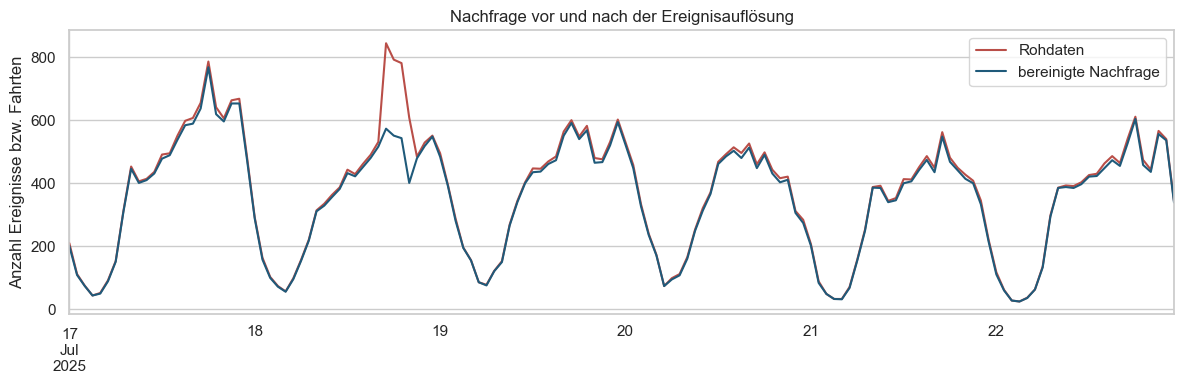

In [28]:
# Nachfrage vor und nach der Ereignisauflösung vergleichen
peak_check = checkpoint.assign(
    pickup_hour=checkpoint["tpep_pickup_datetime"].dt.floor("h"),
    technical_copy=(
        checkpoint["is_technical_replay"]
        | checkpoint["is_payload_duplicate_copy"]
    ),
)

hourly_comparison = (
    peak_check.groupby("pickup_hour")
    .agg(
        raw_rows=("ingest_record_id", "size"),
        technical_copies=("technical_copy", "sum"),
        resolved_demand=(
            "include_demand_after_event_resolution",
            "sum",
        ),
    )
)

period = hourly_comparison.loc["2025-07-17":"2025-07-22"]

ax = period[
    ["raw_rows", "resolved_demand"]
].plot(
    figsize=(12, 4),
    color=["#B94E48", "#1F5A7A"],
    title="Nachfrage vor und nach der Ereignisauflösung",
)

ax.set(
    xlabel="",
    ylabel="Anzahl Ereignisse bzw. Fahrten",
)
ax.legend(["Rohdaten", "bereinigte Nachfrage"])
plt.tight_layout()
plt.show()

In [29]:
peak_hour = period["raw_rows"].idxmax()

display(
    period.loc[
        [peak_hour],
        ["raw_rows", "technical_copies", "resolved_demand"],
    ]
)

,raw_rows,technical_copies,resolved_demand
pickup_hour,,,
2025-07-18 17:00:00,844,257,573


**Entscheidung:** Die 2. Hypothese wird verworfen. Der Peak in den Rohdaten wird überwiegend durch technische Wiederholungen verursacht. Nach Ausschluss der Payload-Kopien und Replays zeigt die bereinigte Nachfrage keinen vergleichbaren Ausschlag. Eine Zeilenzahl in den Rohdaten darf daher nicht ohne vorherige Ereignisauflösung als Nachfrage interpretiert werden.

## 7. Technische und fachliche Kontrollen

In [12]:
reloaded = pd.read_parquet(CHECKPOINT_PATH)

assert sha256_file(DATA_PATH) == SOURCE_SHA256_BEFORE, "Rohdatei wurde verändert"
assert len(reloaded) == len(trips), "Checkpoint muss alle Rohzeilen behalten"
assert reloaded["ingest_record_id"].is_unique
assert reloaded["is_technical_replay"].sum() == 900
assert set(reloaded["replay_match_type"].unique()) == {
    "not_applicable", "exact_payload", "near_duplicate"
}
assert not reloaded.loc[
    reloaded["is_technical_replay"], "include_revenue_after_event_resolution"
].any()
assert reloaded.loc[
    reloaded["event_resolution"].eq("reversal_negative"),
    "include_revenue_after_event_resolution",
].all()

print("Alle Checkpoint-Kontrollen bestanden.")

Alle Checkpoint-Kontrollen bestanden.


## Decision Log der Referenzlösung

| Beobachtung | Evidenz | Entscheidung | Auswirkung |
|---|---|---|---|
| gemeinsamer Nullblock | vollständig mit `payment_type = 0` verbunden | behalten und strukturell dokumentieren | keine Population durch `dropna()` verlieren |
| identischer Payload mit neuer Lineage | Payloadvergleich und spätere Ingestion | spätere technische Kopie kennzeichnen | nicht erneut für Demand oder Revenue zählen |
| kleine Abweichungen bei gleicher Fahrt | Blocking, Toleranzen und Replay-Lineage | kanonischem Ereignis zuordnen | Near-Duplicate nicht erneut zählen |
| positive und negative Fahrtsignatur | gleiches Fahrtmuster, gegensätzliche Beträge | als Gegenbuchungspaar markieren | eine Fahrt für Demand, beide Ereignisse für Revenue |
| Restunsicherheit | Ähnlichkeit allein ist kein Beweis | Rohzeile und Match-Evidenz erhalten | spätere Prüfung bleibt möglich |

## KI-Retrospektive

Ein allgemeiner Auftrag wie «Entferne Duplikate und fehlende Werte» führt leicht zu `dropna()`, `drop_duplicates()` ohne fachliches `subset` oder zum Löschen negativer Beträge. Ein belastbarer Prompt nennt Analyseziel, Spaltenbedeutungen, Definitionen, Toleranzen und verlangte Kontrollausgaben.

Die KI kann Codevarianten und Tests vorschlagen. Die Definition von Fahrt, Finanzereignis und akzeptabler Evidenz bleibt eine fachliche Entscheidung.